
# Student Performance Analytics System

## Project Overview

This project analyses student academic and administrative data stored in a MySQL database. It uses Python-based data analysis and visualization to examine academic performance, attendance, fee payments, backlogs, and placement outcomes.

## Objectives

- Evaluate academic performance across courses and semesters.
- Examine the relationship between attendance and marks.
- Identify data quality issues and inconsistent records.
- Analyse fee payment status, backlogs, and placement outcomes.
- Present findings through visualizations and concise analytical reports.

## Tools and Technologies

Python | MySQL | Pandas | NumPy | Matplotlib | Seaborn | Jupyter Notebook

## Methodology

1. Extract data from MySQL.
2. Inspect and validate the dataset.
3. Clean inconsistent or invalid values where justified.
4. Perform exploratory data analysis.
5. Create visualizations and interpret the results.
6. Export reports and document evidence-based recommendations.

## Expected Outcome

A reproducible analytical workflow that converts student records into understandable performance metrics and supports data-driven academic and administrative decisions.


In [24]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")


## 2. Database Connection

Connect to the existing MySQL database and retrieve the records required for analysis.


In [9]:

import os

print("Current notebook directory:", os.getcwd())
print("database.py available:", os.path.exists("database.py"))


Current notebook directory: C:\Users\Admin\OneDrive\Desktop\student management system
database.py available: True


In [12]:
from database import create_connection

conn = create_connection()

if conn is None:
    raise ConnectionError("Unable to connect to the MySQL database.")


## 3. Data Extraction

Load the existing student records into a Pandas DataFrame for inspection and analysis.



In [14]:

query = """
SELECT
    student_id,
    name,
    age,
    course,
    marks,
    gender,
    city,
    semester,
    attendance_percentage,
    enrollment_date,
    total_fees,
    fees_paid,
    backlogs,
    placement_status
FROM students
ORDER BY student_id;
"""

df = pd.read_sql(query, conn)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (100, 14)


C:\Users\Admin\AppData\Local\Temp\ipykernel_17260\483954702.py:21: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,student_id,name,age,course,marks,gender,city,semester,attendance_percentage,enrollment_date,total_fees,fees_paid,backlogs,placement_status
0,1,raghav,18,Python,50.0,Male,Agra,1,67.0,2023-07-14,30000.0,20000.0,1,Applied
1,2,Anjali Sharma,18,Data Science,90.0,Female,Aligarh,2,74.0,2023-07-27,30000.0,15000.0,2,Not Started
2,3,aa,18,CSE,90.0,Male,Delhi,3,81.0,2023-08-09,60000.0,10000.0,3,Not Started
3,4,Rahul Sharma,19,Python,85.0,Female,Mathura,4,88.0,2023-08-22,30000.0,30000.0,0,Not Started
4,5,Priya Verma,20,Data Science,92.0,Male,Agra,5,95.0,2023-09-04,30000.0,20000.0,1,Placed


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             100 non-null    int64  
 1   name                   100 non-null    str    
 2   age                    100 non-null    int64  
 3   course                 100 non-null    str    
 4   marks                  100 non-null    float64
 5   gender                 100 non-null    str    
 6   city                   100 non-null    str    
 7   semester               100 non-null    int64  
 8   attendance_percentage  100 non-null    float64
 9   enrollment_date        100 non-null    object 
 10  total_fees             100 non-null    float64
 11  fees_paid              100 non-null    float64
 12  backlogs               100 non-null    int64  
 13  placement_status       100 non-null    str    
dtypes: float64(4), int64(4), object(1), str(5)
memory usage: 11.1+ KB


In [16]:
df[["marks", "attendance_percentage"]].describe()

,marks,attendance_percentage
count,100.000000,100.000000
mean,80.520000,79.760000
std,12.479867,11.886772
min,50.000000,60.000000
25%,71.000000,69.000000
50%,84.000000,80.000000
75%,91.000000,90.000000
max,98.000000,100.000000


In [17]:
course_summary = (
    df.groupby("course")
      .agg(
          students=("student_id", "nunique"),
          average_marks=("marks", "mean"),
          average_attendance=("attendance_percentage", "mean")
      )
      .round(2)
      .sort_values("average_marks", ascending=False)
)

display(course_summary)

,students,average_marks,average_attendance
course,,,
Data Science,25,92.04,80.20
BCA,24,88.67,80.79
CSE,25,72.44,79.00
Python,26,69.69,79.12


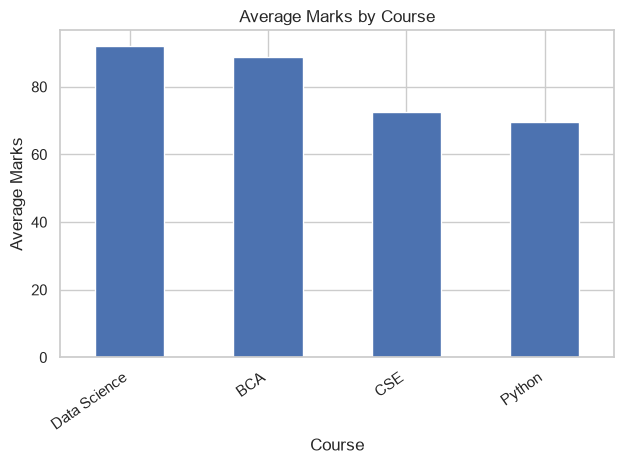

In [18]:
course_summary["average_marks"].plot(kind="bar")

plt.title("Average Marks by Course")
plt.xlabel("Course")
plt.ylabel("Average Marks")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

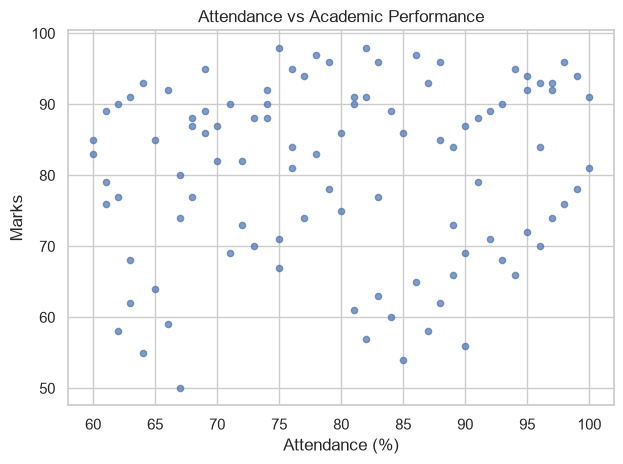

In [19]:
df.plot(
    kind="scatter",
    x="attendance_percentage",
    y="marks",
    alpha=0.7
)

plt.title("Attendance vs Academic Performance")
plt.xlabel("Attendance (%)")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

In [20]:
fees_summary = pd.Series({
    "Total Fees": df["total_fees"].sum(),
    "Fees Collected": df["fees_paid"].sum(),
    "Outstanding Fees": (
        df["total_fees"] - df["fees_paid"]
    ).sum()
})

display(fees_summary.to_frame("Amount"))

,Amount
Total Fees,3750000.0
Fees Collected,1875000.0
Outstanding Fees,1875000.0


In [22]:
df["placement_status"].value_counts(dropna=False)

placement_status
Not Started    60
Applied        20
Placed         20
Name: count, dtype: int64

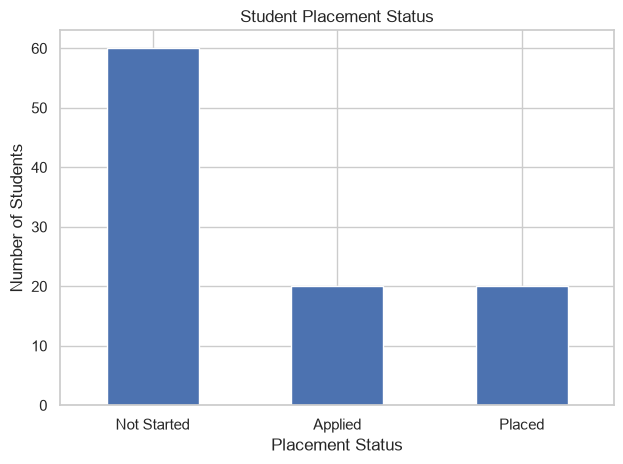

In [23]:
placement_counts = df["placement_status"].value_counts()

placement_counts.plot(kind="bar", rot=0)

plt.title("Student Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()